# Processing of RSS300 Doppler Radar payload data
## Authors: Peter Bauer-Gottwein (pbg@ign.ku.dk)

# Preliminaries
This jupyter notebook documents the data processing workflow for the UAWOS RSS300 Doppler radar payload. We demonstrate the data processing workflow for one recent example from the Orco/Po Rivers. We only include basic Level-2 and Level-3 processing steps. All necessary Level-1 data, auxiliary data and code files to run this notebook are included in a folder "RSS_processing_example", which is distributed with this notebook and is expected to sit in the directory from which this notebook is run. The RSS_processing_example folder also contains a listing of the UAWOS python environment and a corresponding .yaml file. Please install this environment (e.g. using conda) prior to running the notebook. 

### Level 1 data
A RSS300 Doppler radar survey consists of at least one cross section flight across the river. Typically there is one individual set of files for each cross section. Each flight may contain multiple hovering waypoints along the cross section, which have to be separated in data processing. The standard case is that the drone crosses the river twice, i.e. forth and back, looking upstream in on the way forth and downstream on the way back, or vice versa. In some cases, the number of upstream and downstream looking waypoints may not be the same.

The following files (with acquisition UTC time stamps in the file name) will be available for each RSS300 cross section flight:

* A *-position.csv file (e.g. 2025-04-10-13-54-21-position.csv in our example), which contains the drone positioning information from SkyHub.
* A *.-GEOLUXRSS.csv file (e.g. 2025-04-10-13-54-21-GEOLUXRSS.csv in our example), which contains drone positioning information from Skyhub, as well as a column "RSS:Trace", which links selected Doppler Radar traces with corresponding time stamps
* A *-GEOLUXRSS.sgy file (e.g. 2025-04-10-13-54-21-GEOLUXRSS.csv in our example), which contains the full trace output (i.e. radargram) from the RSS300 Doppler radar system.

# Auxiliary data
The following auxiliary data files and items are required to process an LX80 dataset:
* A cross section shapefile (chain_XSline_Cavour_utm.shp in our case). This shapefile should be in the target projection of the survey (EPSG:32632) in our case. It should be a point shapefile with points every 0.2 m along the cross section line. Depending on the size of the river etc., other point spacings may be used. You can produce this file from any river cross section line shapefile, for instance using the QGIS plugin "QChainage". The usual convention is that the cross section coordinate should increase from the left back to the right bank of the river (left and right are defined looking downstream), and that coordinate 0 should be at the intersection with the river centerline. If ground truth data is available, the cross section line may be placed along the ground truth points, to facilitate direct comparison between WPR and ground truth data.
* A geotiff file giving the elevation of the target geoid above the WGS84 ellipsoid at suitable spatial resolution (e.g. 10m) In our example, we use ITALGEO05 as the geoid and the file is ITALGEO2005_Orco_negative.tif.
* The EPSG code for the target projection (EPSG:32632 in our case)
* The EPSG code for the target geoid (ITALGEO05 in our case)
* The identifier of the chainage field in the attribute table of the cross section shapefile. If you use QChainage, the identifier will be "cngmeters"
* The flight altitude above the water. The standard scenario is that the Doppler is deployed 4m above the water surface.

# Processing
## 1. Preparing the cross section shapefile
This can be done in QGIS. Go through the following steps:
1. Load the *position.csv file into QGIS as a comma-separated text layer.
2. Create a new line shapefile
3. Create a new shape feature for the reference cross section line
4. Chop up the line into equally spaced points (e.g. 0.2 m), using for instance QGIS plugin "QChainage"
5. Adjust the "cngmeters" field to ensure coordinate zero is at the river centerline.

## 2. Fligth Pre-Processing
First, let's import all required packages:

In [1]:
import os
my_path = r'h:\UAWOS\uawos_data_processing' + os.sep + 'RSS_processing_example'
import pandas as pd

from UAWOS_RSS_flight import UAWOS_RSS_flight

We provide inputs for auxiliary data and flight data. The flight data block can be copied as many times as there are profile flights in the survey:

In [2]:
Orco_general_attributes = dict()

Orco_general_attributes['xy_EPSG'] = 'EPSG:32632'
Orco_general_attributes['z_EPSG'] = 'ITALGEO05'
Orco_general_attributes['geoid_tiff'] = my_path + os.sep + 'ITALGEO2005_Orco_negative.tif'
Orco_general_attributes['chainage_field'] = 'cngmeter'

Orco_1_attributes = Orco_general_attributes.copy()

Orco_1_attributes['name_posfile'] = my_path + os.sep + '2025-04-10-13-54-21-position.csv'
Orco_1_attributes['name_RSSfile'] = my_path + os.sep + '2025-04-10-13-54-21-GEOLUXRSS.csv'
Orco_1_attributes['name_segyfile'] = my_path + os.sep + '2025-04-10-13-54-21-GEOLUXRSS.sgy'
Orco_1_attributes['name_wpfile'] = my_path + os.sep + '2025-04-10-13-54-21-waypoints.xlsx'# This will be created during preprocessing, pls see below
Orco_1_attributes['name_ppkfile'] = r''# if RTK was off during flight, the path to a corresponding ppk file that contains the relevant time stamp range can be provided here
Orco_1_attributes['in_situ_L3'] = r''
Orco_1_attributes['refline_file'] = my_path + os.sep + 'chain_XSline_Cavour_utm.shp'
Orco_1_attributes['RTK_on'] = True
Orco_1_attributes['CL_dist_threshold'] = 100 
Orco_1_attributes['L2_output'] = my_path + os.sep + r'Level_2\2025-04-10-13-37-22.csv'
Orco_1_attributes['L3_output'] = my_path + os.sep + r'Level_3\2025-04-10-13-37-22.csv'

Orco_1 = UAWOS_RSS_flight(Orco_1_attributes)

UAWOS RSS flight class constructor
Wavelength of Doppler radar in m: 0.0125
Doppler shift per unit speed in 1/m or Hz/(m/s):  160.0
Spectral resolution of Doppler spectrum in Hz:  1.182736


First, we visualize the flight radargram to get an overview and evaluate data quality:

Sampling rate:  0.032
Number of traces in dataset:  1248
Number of samples in each trace:  4096


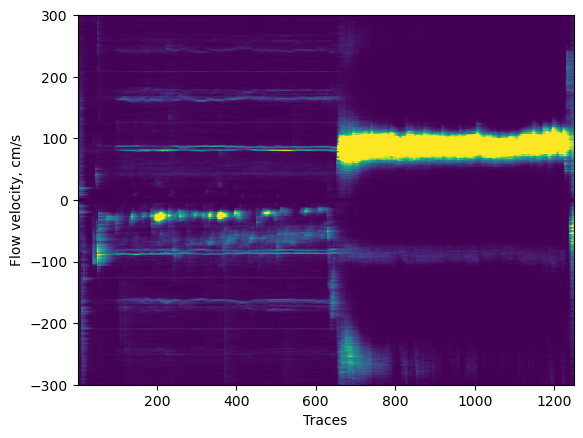

In [3]:
Orco_1.visualize_radargram()

From the inspection of the fligth path (*-position.csv file, for instance in QGIS), it is clear that the drone first covered a number of upstream looking waypoints and then, around trace number 640, turned around and occupied a number of downstream-looking waypoints. From the radargram above, it is clear that good data quality was only achieved in the downstream-looking scenario, while the upstream-looking waypoints appear very noisy. We have generally observed that downstream-looking data seems to be of better quality than upstream-looking. The reasons for this are not entirely understood. Generally, the quality of Doppler data depends on the flow speed, the roughness of the water surface, drone stability and other issues.

Next, let us inspect the drone navigation data and identify the waypoints that the drone occupied during the flight:

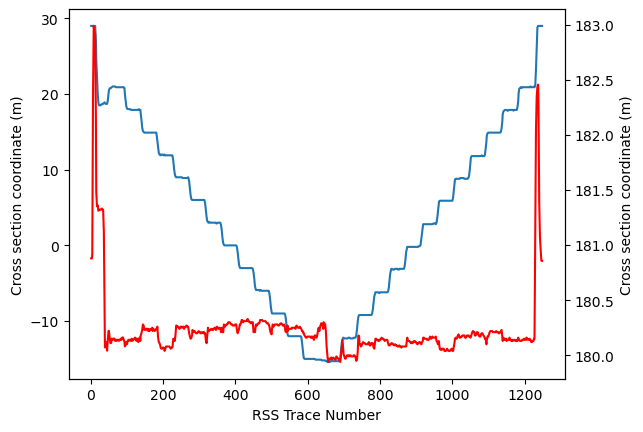

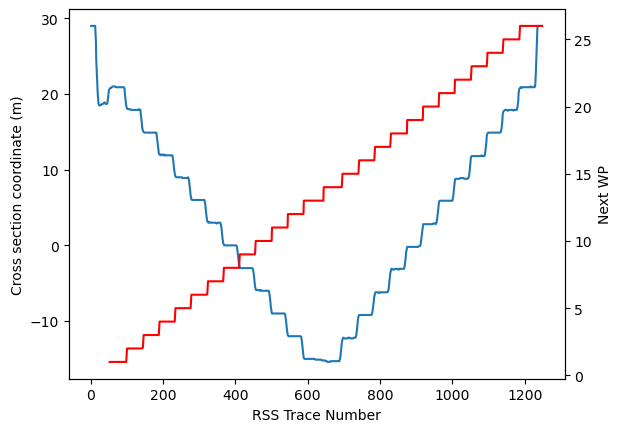

In [4]:
Orco_1 = Orco_1.process_RSS_flight()
Orco_1.plot_Alt_XScoord_vs_Tnum()
Orco_1.plot_WP_XScoord_vs_Tnum()

Now we use the "Next WP" column of the *-position.csv file to identify the traces belonging to each waypoint. This information is written into the waypoint file:

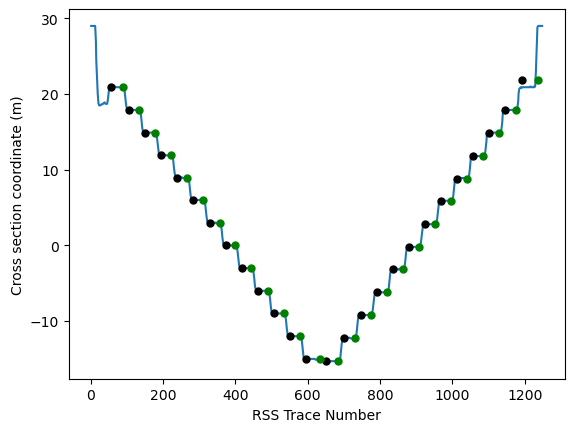

In [5]:
Orco_1.make_WPfile()
Orco_1.plot_WPdata()

We can now visually check the waypoint identification:

Waypoint identification can now be manually adjusted if necessary, by modifying the waypoint excel file manually. In this case, we can move the start trace of the first waypoint to 60 and the end trace of the last waypoint to 1225.

## 3. Main Processing

We can now proceed with the main processing steps:

The first step extracts and displays radargrams for each waypoint, computes and displays the average spectrum for the waypoint, fits a single (or double) peak Gaussian model to the spectrum and displays the fit.

Sampling rate:  0.032
Number of traces in dataset:  1248
Number of samples in each trace:  4096


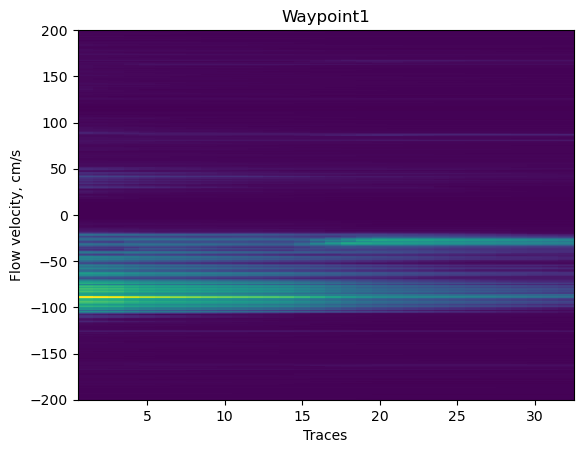

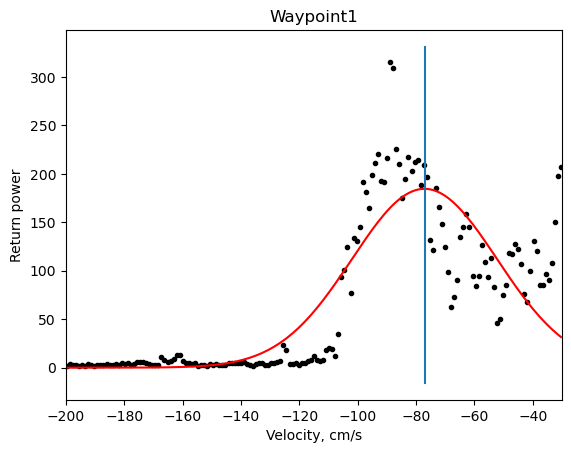

------------ Waypoint 1------------
Phi=42.07359303826556
Vel=-77.08425685829978
an error occured in the fitting
 Waypoint 1 could not be fitted


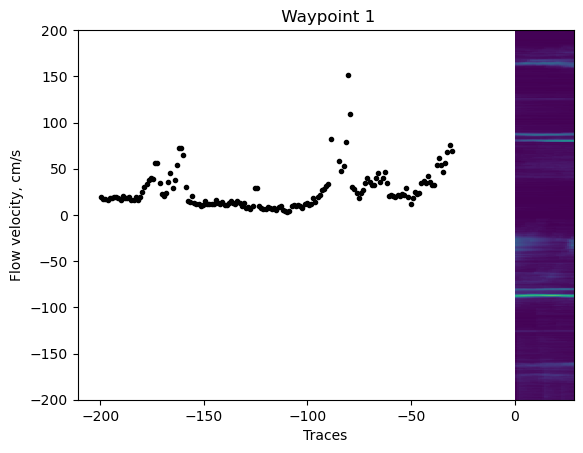

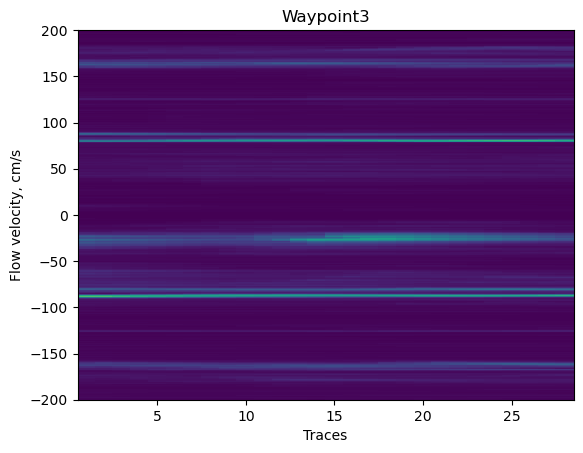

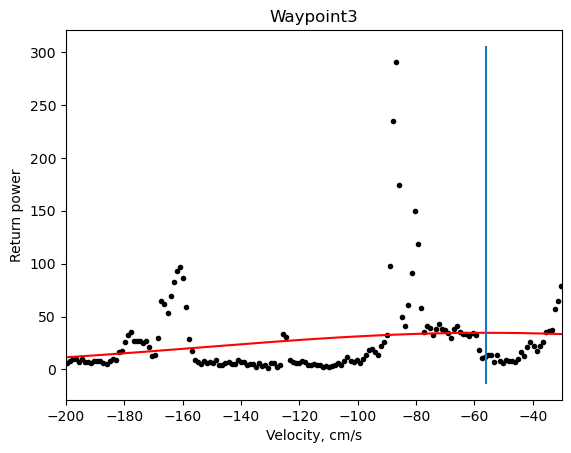

------------ Waypoint 3------------
Phi=37.36901117643541
Vel=-56.11130448478585
an error occured in the fitting
 Waypoint 3 could not be fitted


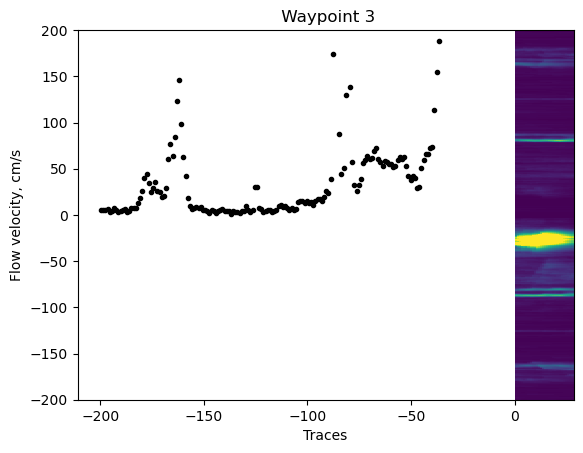

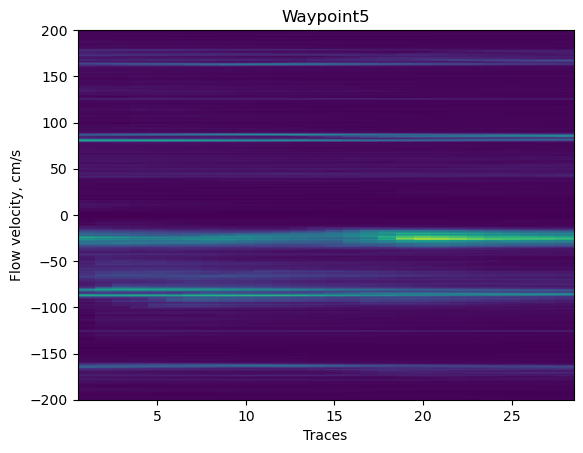

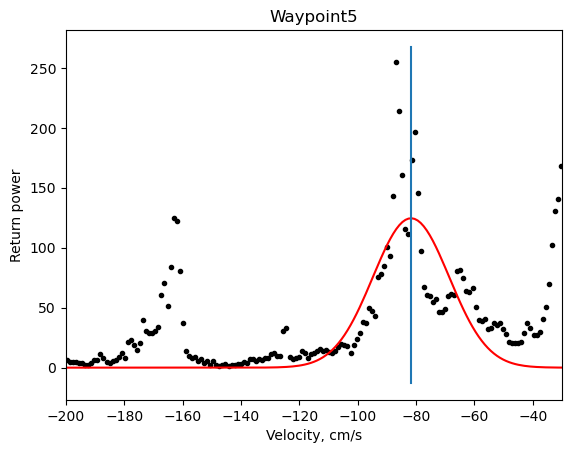

------------ Waypoint 5------------
Phi=37.96184520699442
Vel=-81.70343215372925


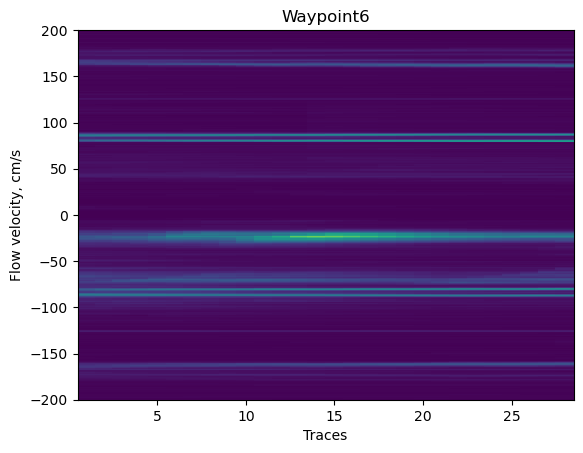

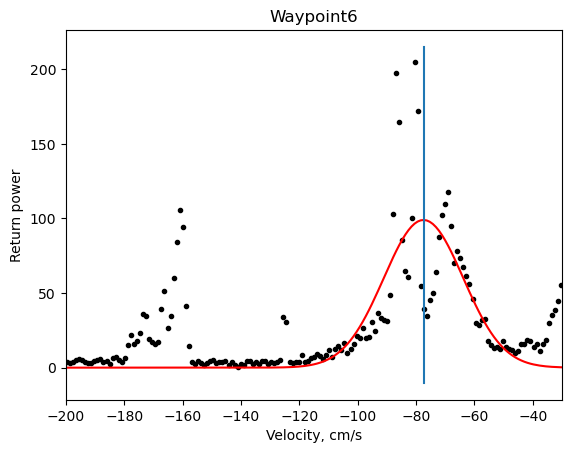

------------ Waypoint 6------------
Phi=27.29076184905852
Vel=-77.43139802855251


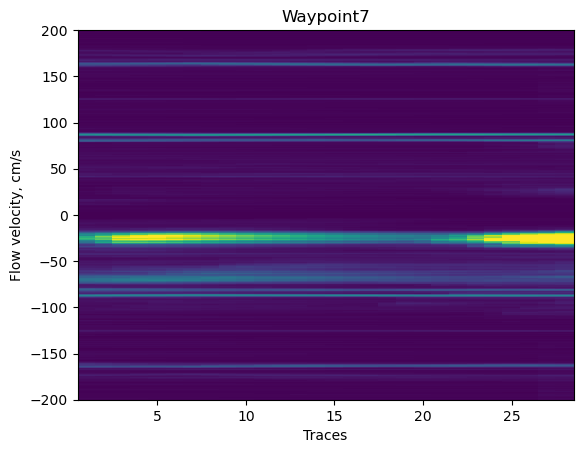

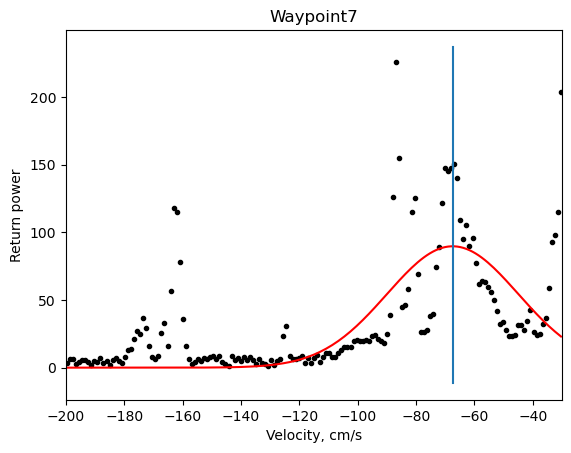

------------ Waypoint 7------------
Phi=34.52744419224596
Vel=-67.4413540781604


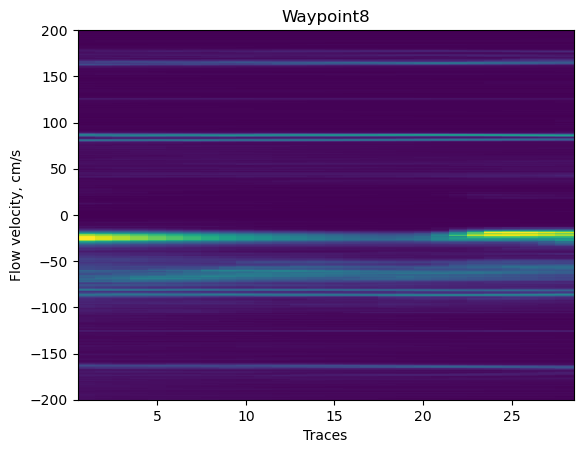

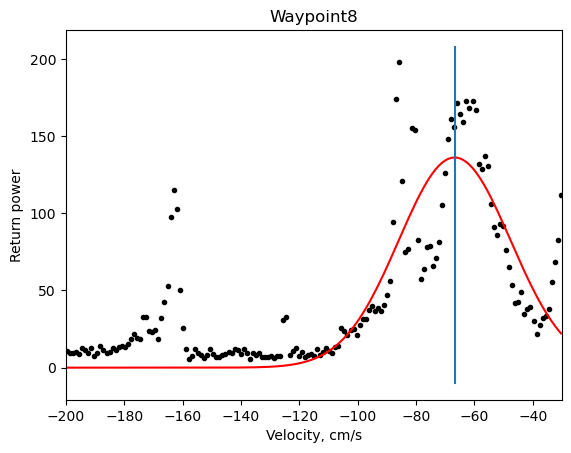

------------ Waypoint 8------------
Phi=29.24686291752159
Vel=-66.76129468536584


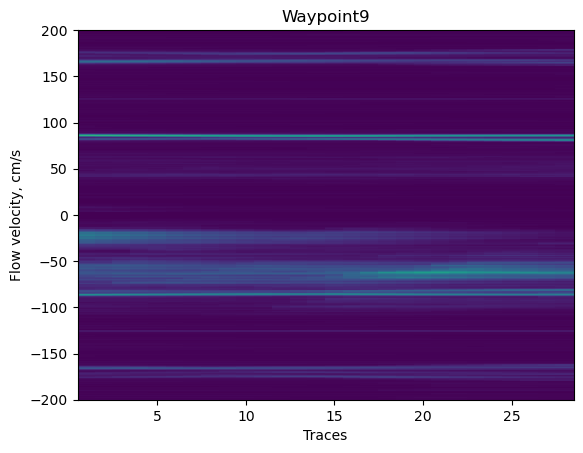

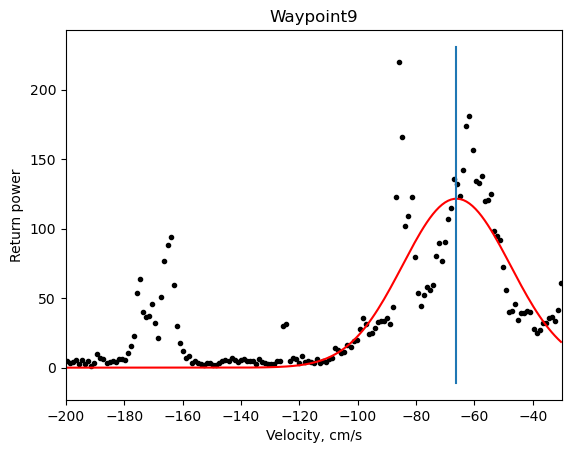

------------ Waypoint 9------------
Phi=27.923015099735263
Vel=-66.13585447329655


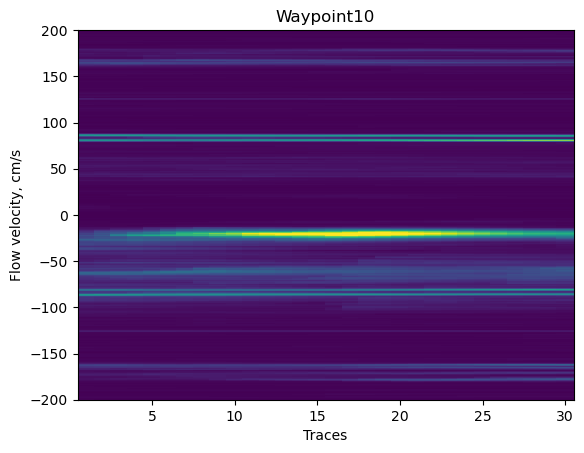

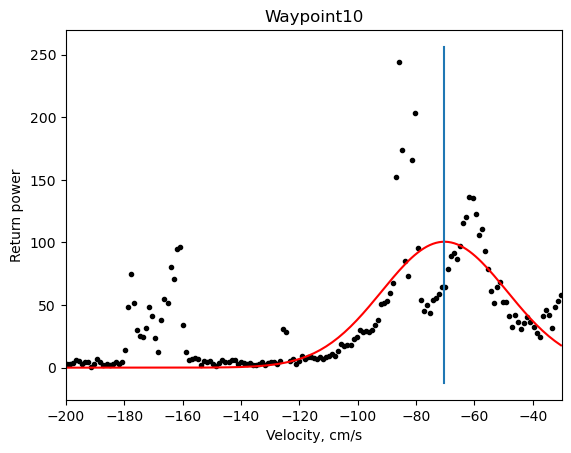

------------ Waypoint 10------------
Phi=31.060976311950636
Vel=-70.27732143668102


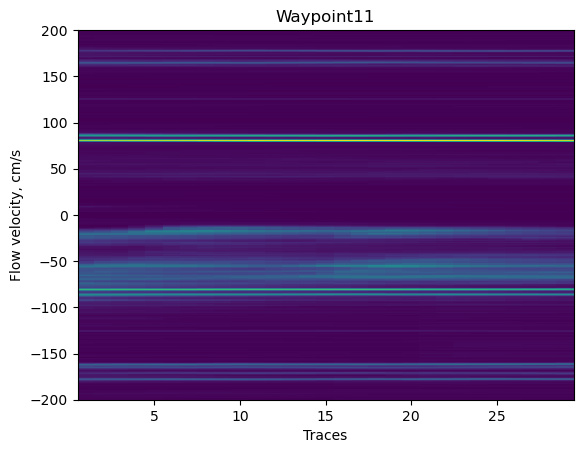

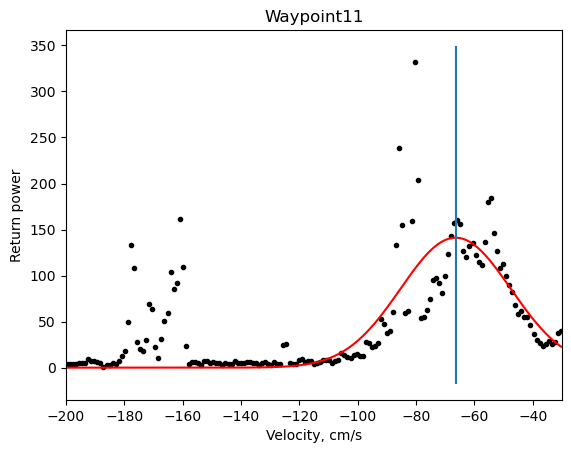

------------ Waypoint 11------------
Phi=39.87399644478404
Vel=-66.42032346310252


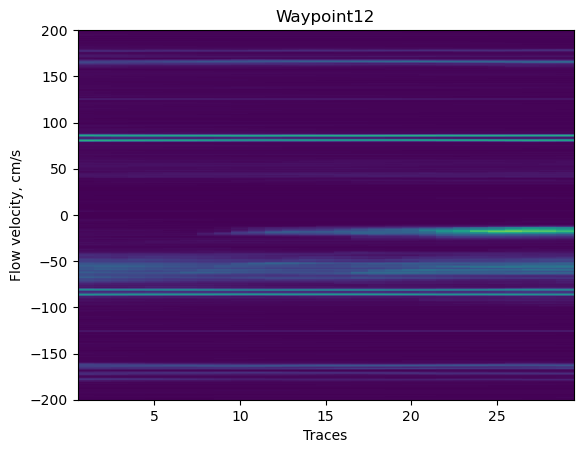

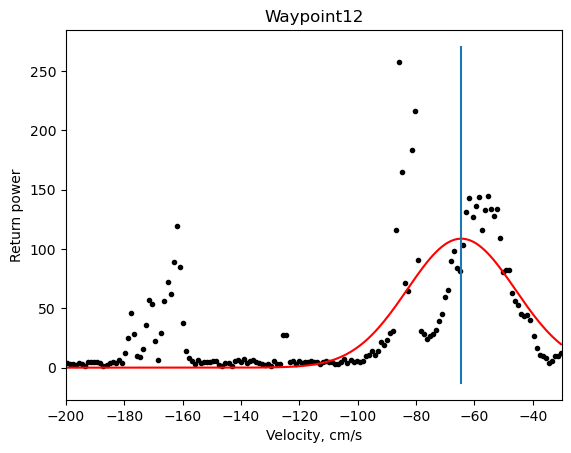

------------ Waypoint 12------------
Phi=35.523616613313905
Vel=-64.4890950519236


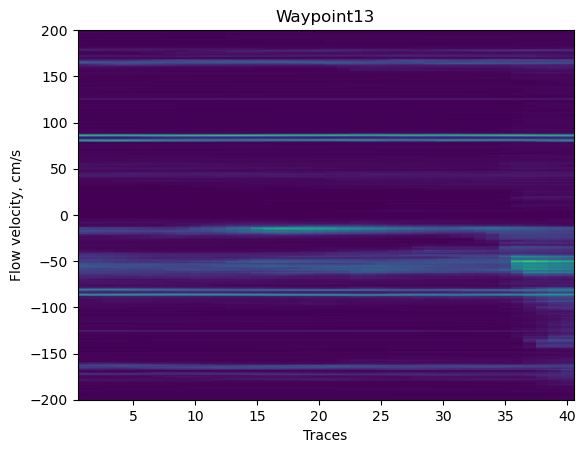

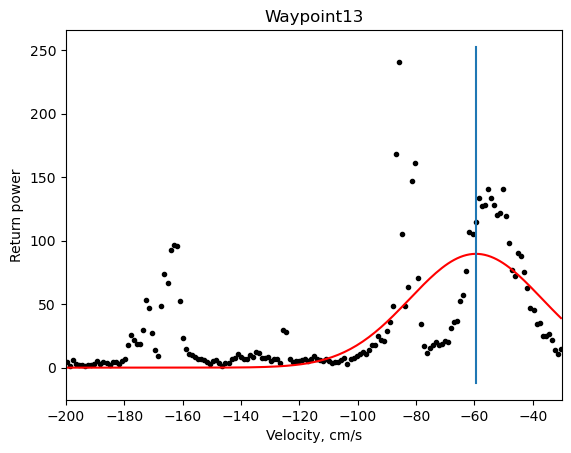

------------ Waypoint 13------------
Phi=35.05687979549567
Vel=-59.475007437134515


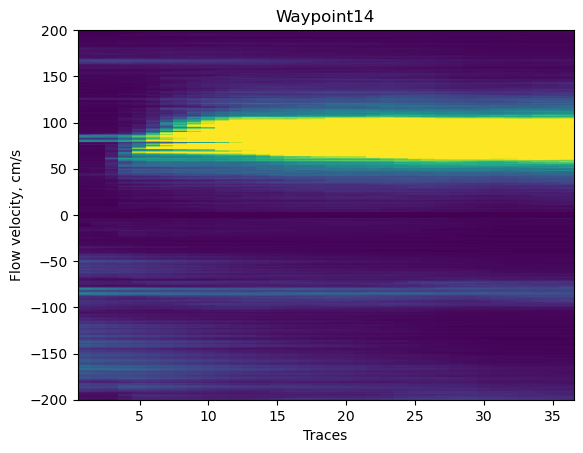

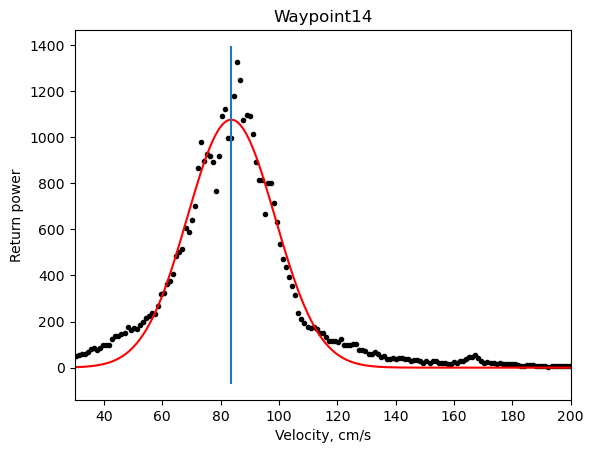

------------ Waypoint 14------------
Phi=62.04354524404699
Vel=83.61056144891587


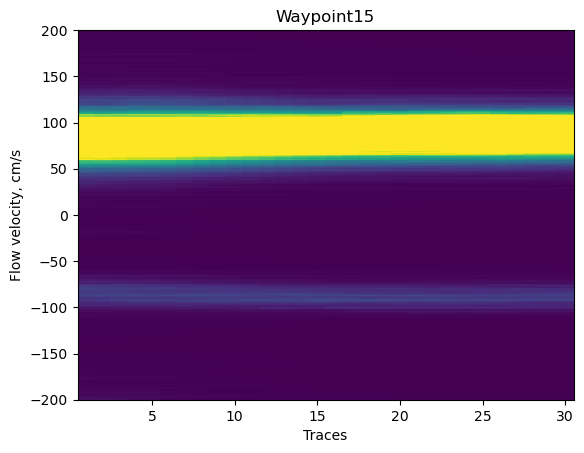

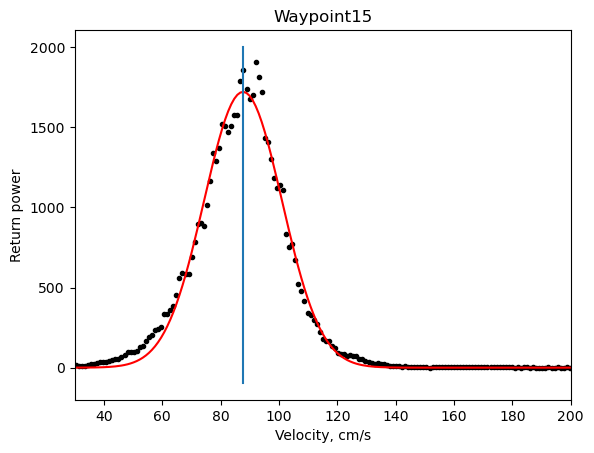

------------ Waypoint 15------------
Phi=57.80485043756703
Vel=87.66493310665925


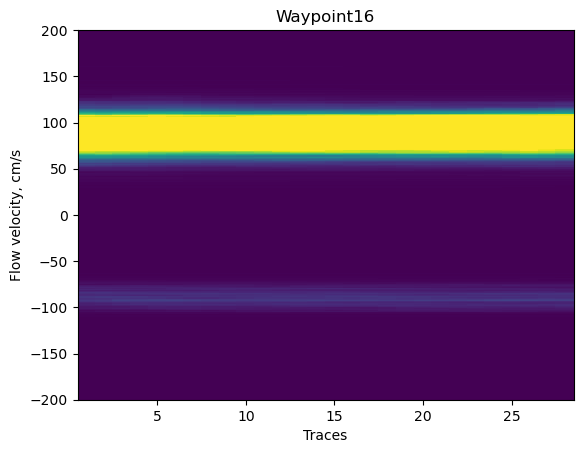

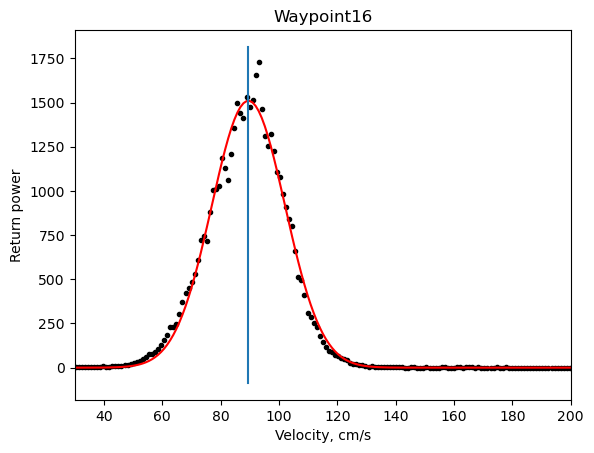

------------ Waypoint 16------------
Phi=45.26950491473023
Vel=89.51039011420917


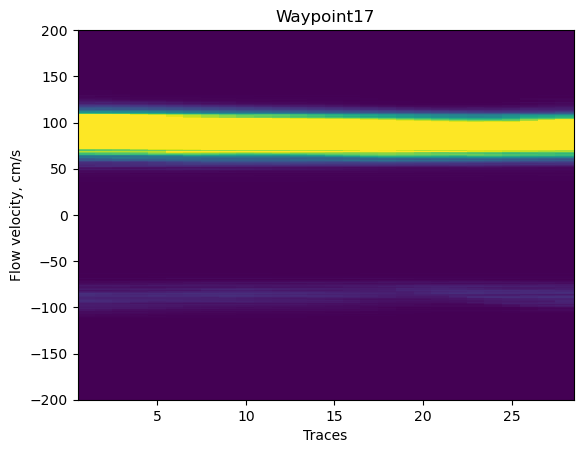

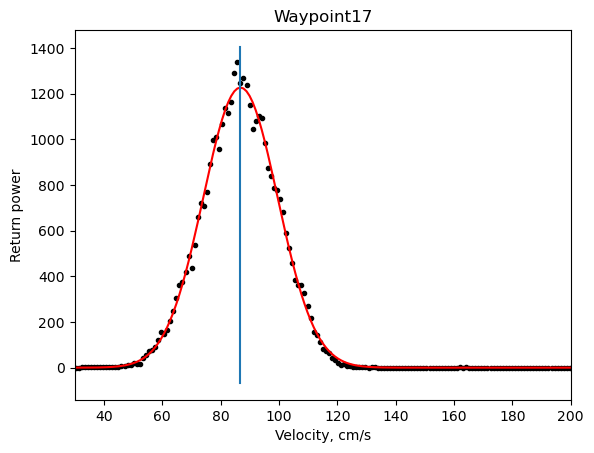

------------ Waypoint 17------------
Phi=24.45758129399034
Vel=86.77754185996095


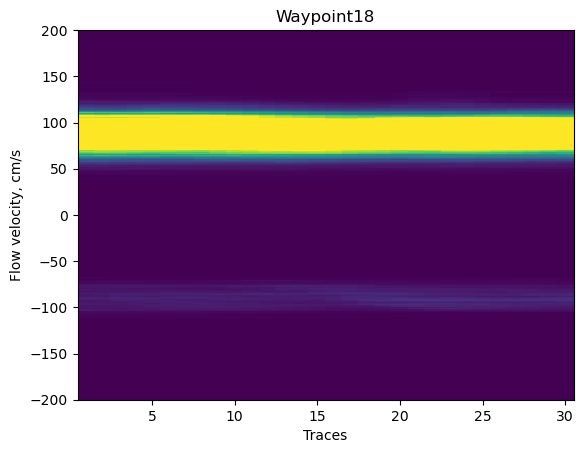

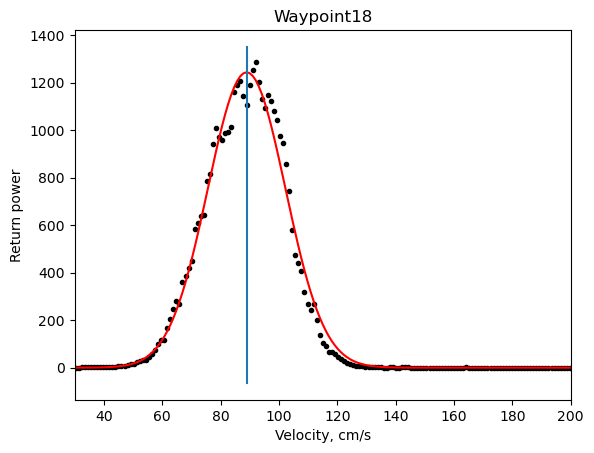

------------ Waypoint 18------------
Phi=42.079503190800814
Vel=88.90956669678526


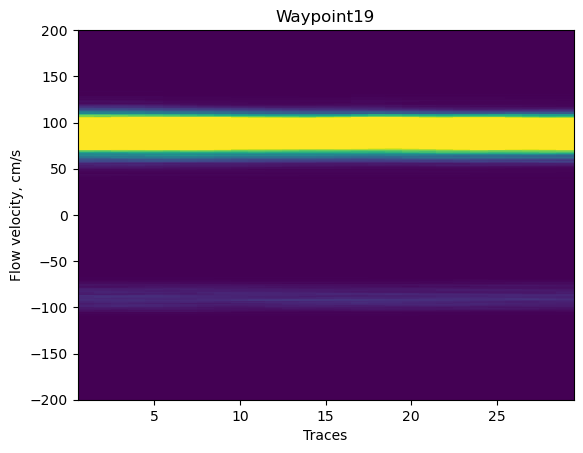

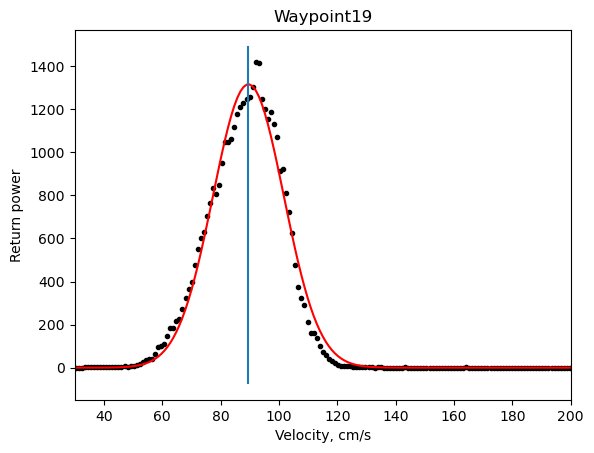

------------ Waypoint 19------------
Phi=44.03444471148479
Vel=89.50530954800298


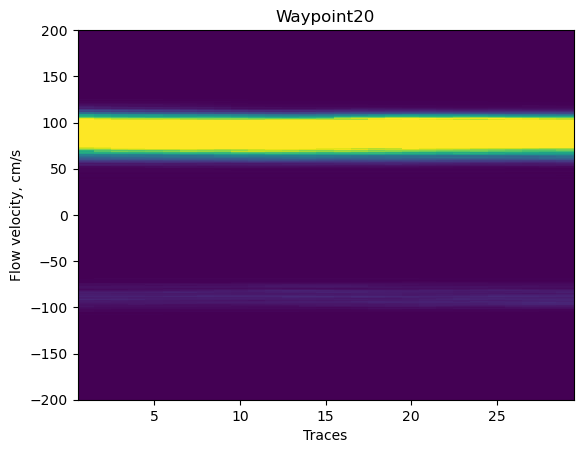

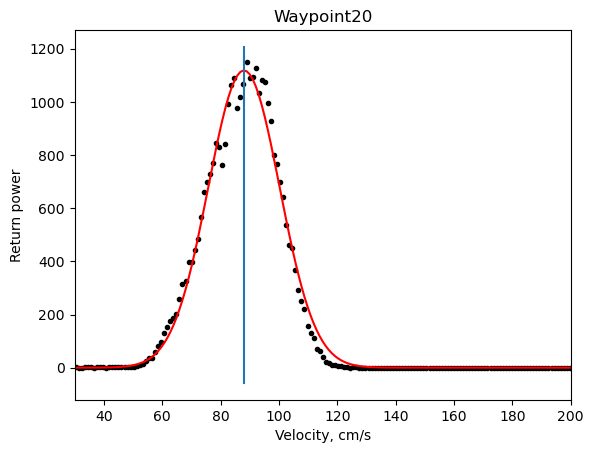

------------ Waypoint 20------------
Phi=34.9346982308396
Vel=87.98410429271169


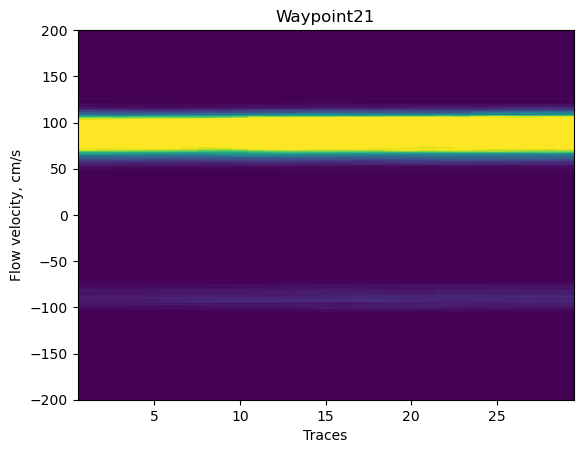

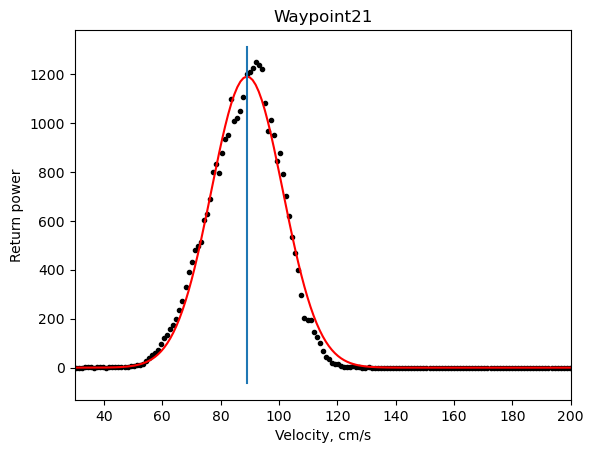

------------ Waypoint 21------------
Phi=37.7822883456248
Vel=89.05511628263828


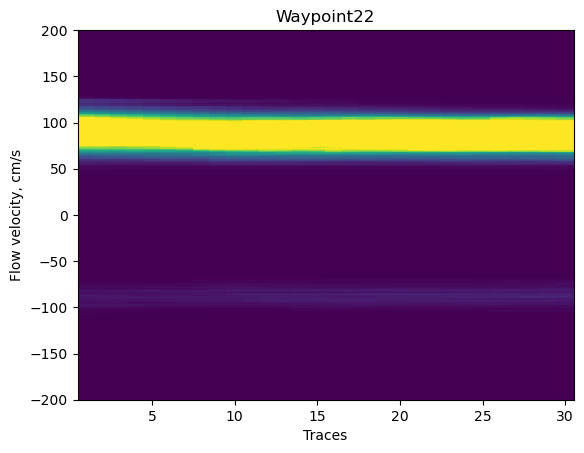

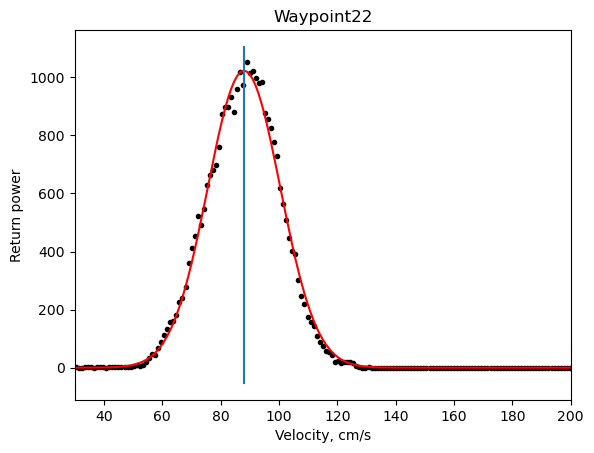

------------ Waypoint 22------------
Phi=21.077074598606835
Vel=88.00525467782391


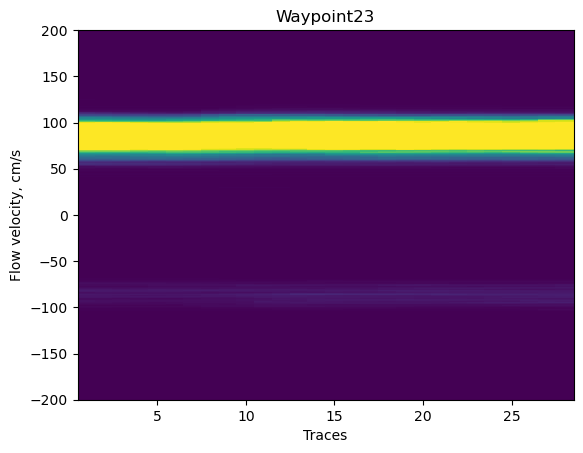

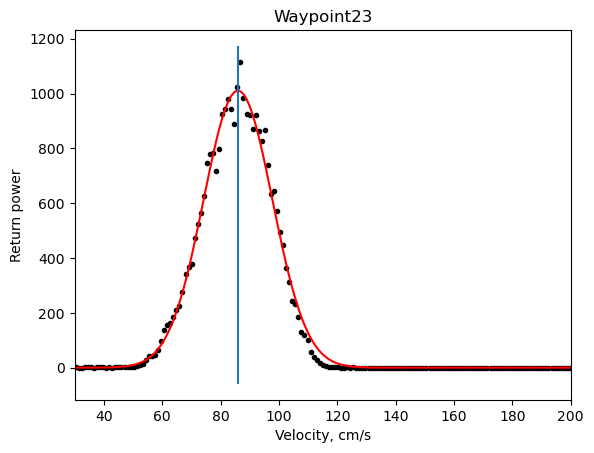

------------ Waypoint 23------------
Phi=26.617329215689512
Vel=85.94137978377398


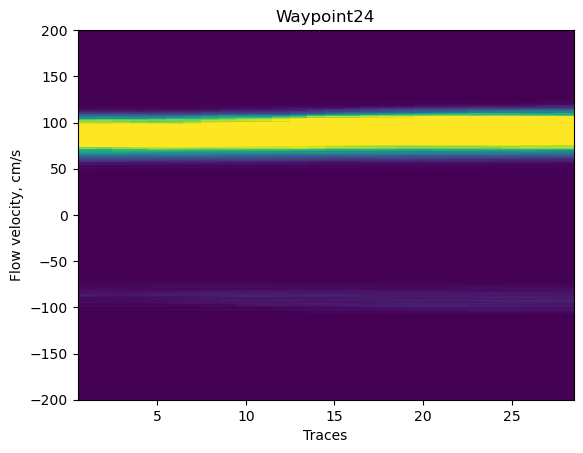

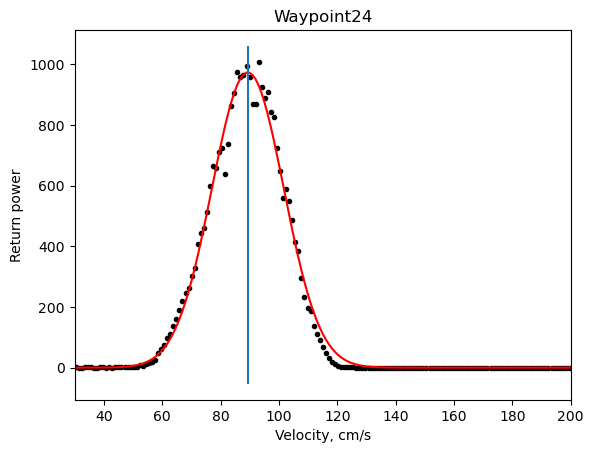

------------ Waypoint 24------------
Phi=27.396894186872096
Vel=89.31356531524197


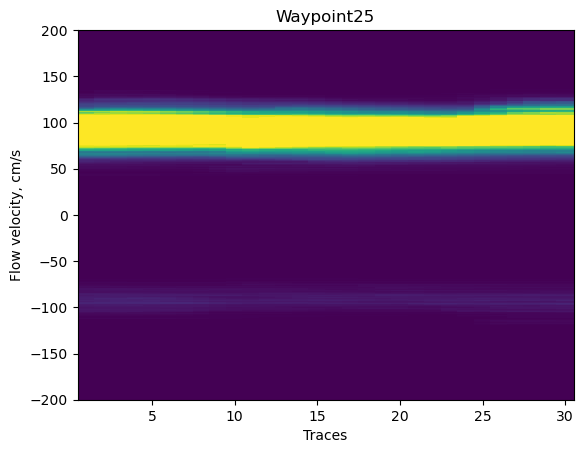

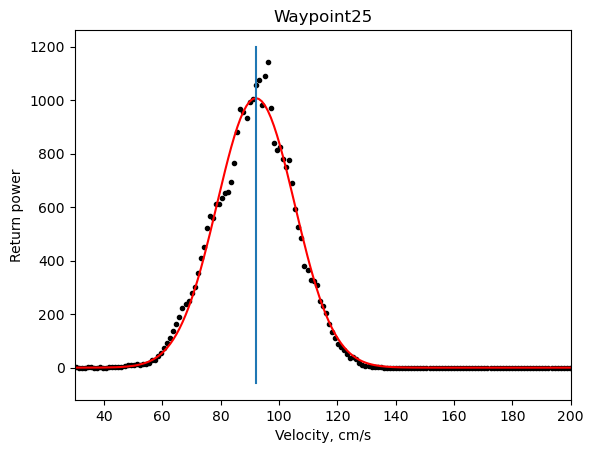

------------ Waypoint 25------------
Phi=31.849539602572783
Vel=92.05729135602314


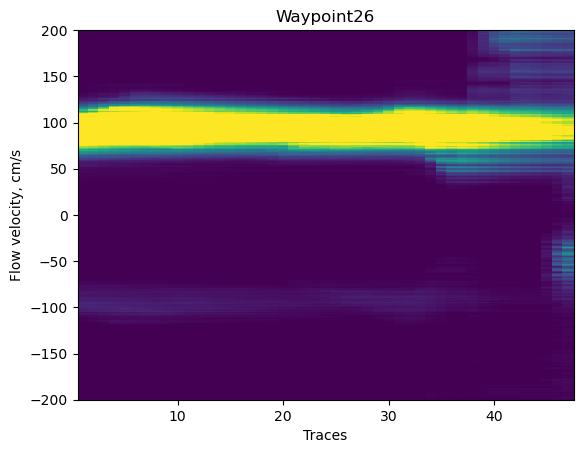

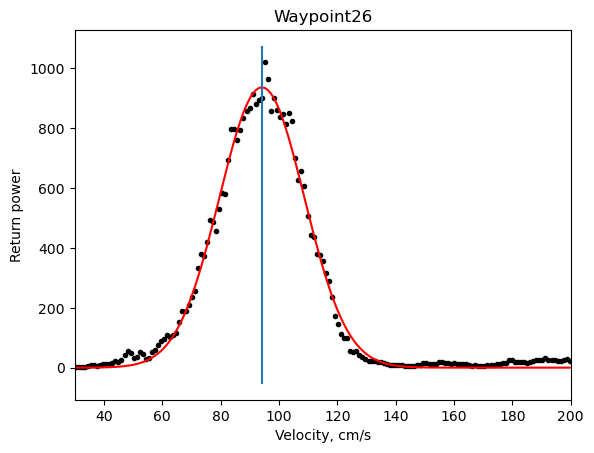

------------ Waypoint 26------------
Phi=27.107367635024236
Vel=94.13352912360737


In [6]:
Orco_1.process_RSS_data()

The next step plots the surface velocity data along the cross section. One can clearly see the difference between the upstream and downstream looking data.

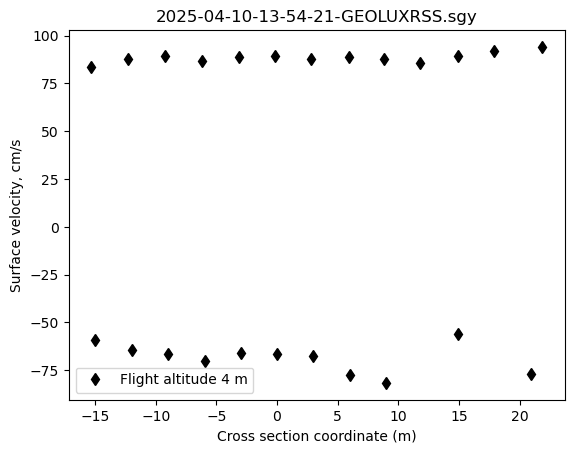

In [7]:
Orco_1.plot_RSS_res()

And lastly, the generation of the L2 and L3 final output files:

In [8]:
#%% L3 generation
if not os.path.exists(my_path + os.sep + 'Level_2'):
    os.makedirs(my_path + os.sep + 'Level_2')
if not os.path.exists(my_path + os.sep + 'Level_3'):
    os.makedirs(my_path + os.sep + 'Level_3')
Orco_1.L2_L3_generation()